# Semana 10 — recuperación de resultados 2.5D (sin reentrenar)

Este notebook **no entrena de nuevo**. Recupera el entrenamiento completo de 60 épocas desde el checkpoint, el historial JSON y el log que ya quedaron guardados.

Incluye verificación de NaN/Inf, curvas de entrenamiento, las nueve metas del proyecto y una evaluación volumétrica completa opcional (desactivada por defecto).

In [1]:
import os
import re
import sys
import json
from pathlib import Path

def encontrar_raiz(inicio: Path) -> Path:
    for candidato in (inicio, *inicio.parents):
        if (candidato / "src" / "train_s10.py").exists() and (candidato / "README.md").exists():
            return candidato
    raise FileNotFoundError("No encontré la raíz del repositorio.")

ROOT = encontrar_raiz(Path.cwd().resolve())
os.chdir(ROOT)
os.environ["PYTHONUTF8"] = "1"
print("Raíz:", ROOT)
print("Python:", sys.version.split()[0], "| ejecutable:", sys.executable)

Raíz: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main
Python: 3.12.6 | ejecutable: e:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\.venv\Scripts\python.exe


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown

NOMBRE = "h6_25d_noema_nocudnn_w32_e60_s42_local"
SALIDA = ROOT / "outputs" / "s10" / "local_gpu_25d"
CHECKPOINT = SALIDA / f"{NOMBRE}.pth"
HISTORIAL_JSON = SALIDA / f"{NOMBRE}.json"
LOG_ENTRENAMIENTO = SALIDA / f"{NOMBRE}_train.log"
VALIDACION_JSON = SALIDA / f"{NOMBRE}_val.json"
LOG_VALIDACION = SALIDA / f"{NOMBRE}_eval.log"
FIGURAS = SALIDA / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

for etiqueta, ruta in {"checkpoint": CHECKPOINT, "historial": HISTORIAL_JSON, "log": LOG_ENTRENAMIENTO}.items():
    if not ruta.exists():
        raise FileNotFoundError(f"Falta {etiqueta}: {ruta}")
with HISTORIAL_JSON.open(encoding="utf-8") as f:
    entrenamiento = json.load(f)
print("Checkpoint:", CHECKPOINT)
print("Duración: %.1f minutos (%.2f horas)" % (entrenamiento["minutes"], entrenamiento["minutes"] / 60))
print("Terminó antes de tiempo:", entrenamiento["stopped_early"])
print("Figuras:", FIGURAS)

Checkpoint: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu_25d\h6_25d_noema_nocudnn_w32_e60_s42_local.pth
Duración: 467.2 minutos (7.79 horas)
Terminó antes de tiempo: False
Figuras: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu_25d\figures


## 1. Integridad del checkpoint

La entrada 2.5D usa tres canales: corte anterior, central y siguiente. También comprobamos que los pesos guardados no tengan NaN ni infinitos.

In [3]:
checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
estado = checkpoint["model"]
nan_total = inf_total = elementos = 0
for tensor in estado.values():
    if torch.is_tensor(tensor) and tensor.is_floating_point():
        elementos += tensor.numel()
        nan_total += int(torch.isnan(tensor).sum())
        inf_total += int(torch.isinf(tensor).sum())
args = checkpoint.get("args", entrenamiento.get("args", {}))
resumen_checkpoint = pd.Series({
    "época del checkpoint": checkpoint.get("epoch"),
    "context": args.get("context"),
    "canales de entrada": 2 * int(args.get("context", 0)) + 1,
    "base_channels": args.get("base_channels"),
    "EMA": args.get("ema"),
    "cuDNN desactivado": args.get("disable_cudnn"),
    "parámetros flotantes revisados": elementos,
    "valores NaN": nan_total,
    "valores Inf": inf_total,
}, name="valor")
display(resumen_checkpoint.to_frame())
assert nan_total == 0 and inf_total == 0, "El checkpoint contiene valores no finitos."
print("OK: checkpoint íntegro y finito.")

,valor
época del checkpoint,None
context,1
canales de entrada,3
base_channels,32
EMA,0.0
cuDNN desactivado,True
parámetros flotantes revisados,2740990
valores NaN,0
valores Inf,0


OK: checkpoint íntegro y finito.


## 2. Reconstrucción del historial

El JSON guarda las evaluaciones (épocas 1, 5, 10, …, 60) y el log guarda la pérdida de las 60 épocas.

In [4]:
historial = pd.DataFrame(entrenamiento["history"]).sort_values("epoch").reset_index(drop=True)
patron = re.compile(r"epoch\s+(\d+)\s+loss=([0-9.eE+-]+)")
filas_loss = []
for linea in LOG_ENTRENAMIENTO.read_text(encoding="utf-8", errors="replace").splitlines():
    m = patron.search(linea)
    if m:
        filas_loss.append({"epoch": int(m.group(1)), "loss": float(m.group(2))})
loss_epocas = pd.DataFrame(filas_loss).drop_duplicates("epoch", keep="last").sort_values("epoch")
epoca_mejor = int(historial.loc[historial["score"].idxmax(), "epoch"])
ultima = historial.iloc[-1]
mejor = entrenamiento["best"]
print(f"Pérdidas recuperadas: {len(loss_epocas)}/60")
print(f"Evaluaciones recuperadas: {len(historial)}")
print(f"Mejor checkpoint por score compuesto: época {epoca_mejor}")
print(f"Última evaluación: época {int(ultima.epoch)}")

Pérdidas recuperadas: 60/60
Evaluaciones recuperadas: 13
Mejor checkpoint por score compuesto: época 45
Última evaluación: época 60


In [5]:
OBJETIVOS = {
    "classification_f1_macro": ("Clasificación F1 macro", 0.85),
    "classification_auc_macro": ("Clasificación AUC macro", 0.85),
    "detection_iou_mean": ("Detección IoU media", 0.65),
    "detection_map50": ("Detección mAP50", 0.65),
    "detection_map50_95": ("Detección mAP50:95", 0.40),
    "segmentation_dice_macro": ("Segmentación Dice macro", 0.85),
    "segmentation_iou_macro": ("Segmentación IoU macro", 0.70),
    "instance_dice_matched": ("Instancias Dice emparejado", 0.85),
    "instance_iou_matched": ("Instancias IoU emparejado", 0.70),
}
filas = []
for clave, (nombre, objetivo) in OBJETIVOS.items():
    valor_mejor, valor_final = float(mejor[clave]), float(ultima[clave])
    filas.append({
        "métrica": nombre,
        f"mejor (época {epoca_mejor})": valor_mejor,
        f"final (época {int(ultima.epoch)})": valor_final,
        "objetivo": objetivo,
        "margen mejor": valor_mejor - objetivo,
        "cumple": "SÍ" if valor_mejor >= objetivo else "NO",
    })
tabla_objetivos = pd.DataFrame(filas).set_index("métrica")
display(tabla_objetivos.style.format({
    f"mejor (época {epoca_mejor})": "{:.4f}",
    f"final (época {int(ultima.epoch)})": "{:.4f}",
    "objetivo": "{:.2f}", "margen mejor": "{:+.4f}",
}))
cumplidas = int((tabla_objetivos["cumple"] == "SÍ").sum())
print(f"Resultado: {cumplidas}/{len(tabla_objetivos)} objetivos cumplidos.")

,mejor (época 45),final (época 60),objetivo,margen mejor,cumple
métrica,,,,,
Clasificación F1 macro,0.9832,0.9826,0.85,+0.1332,SÍ
Clasificación AUC macro,0.9976,0.9965,0.85,+0.1476,SÍ
Detección IoU media,0.9206,0.9190,0.65,+0.2706,SÍ
Detección mAP50,0.9401,0.9367,0.65,+0.2901,SÍ
Detección mAP50:95,0.8639,0.8602,0.40,+0.4639,SÍ
Segmentación Dice macro,0.9666,0.9664,0.85,+0.1166,SÍ
Segmentación IoU macro,0.9358,0.9352,0.70,+0.2358,SÍ
Instancias Dice emparejado,0.8623,0.8659,0.85,+0.0123,SÍ
Instancias IoU emparejado,0.7958,0.7997,0.70,+0.0958,SÍ


Resultado: 9/9 objetivos cumplidos.


## 3. Curva de pérdida de las 60 épocas

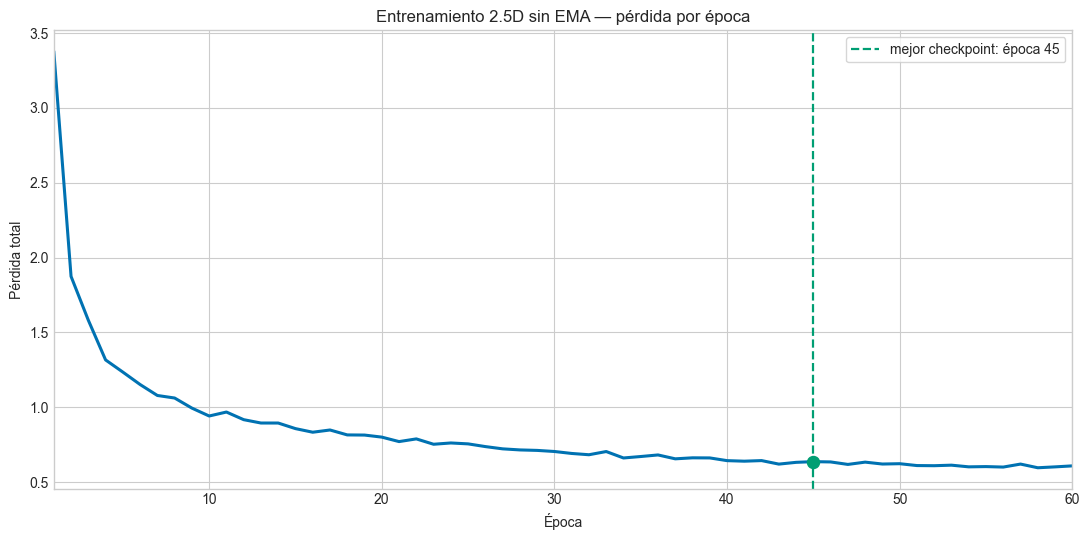

Guardada: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu_25d\figures\perdida_entrenamiento_25d.png


In [6]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(loss_epocas["epoch"], loss_epocas["loss"], color="#0072B2", linewidth=2.2)
ax.axvline(epoca_mejor, color="#009E73", linestyle="--", linewidth=1.6, label=f"mejor checkpoint: época {epoca_mejor}")
valor_loss_mejor = loss_epocas.loc[loss_epocas.epoch.eq(epoca_mejor), "loss"]
if not valor_loss_mejor.empty:
    ax.scatter([epoca_mejor], [valor_loss_mejor.iloc[0]], s=75, color="#009E73", zorder=5)
ax.set(title="Entrenamiento 2.5D sin EMA — pérdida por época", xlabel="Época", ylabel="Pérdida total")
ax.set_xlim(1, 60)
ax.legend(frameon=True)
fig.tight_layout()
ruta_loss = FIGURAS / "perdida_entrenamiento_25d.png"
fig.savefig(ruta_loss, dpi=170, bbox_inches="tight")
plt.show()
print("Guardada:", ruta_loss)

## 4. Evolución de las métricas principales

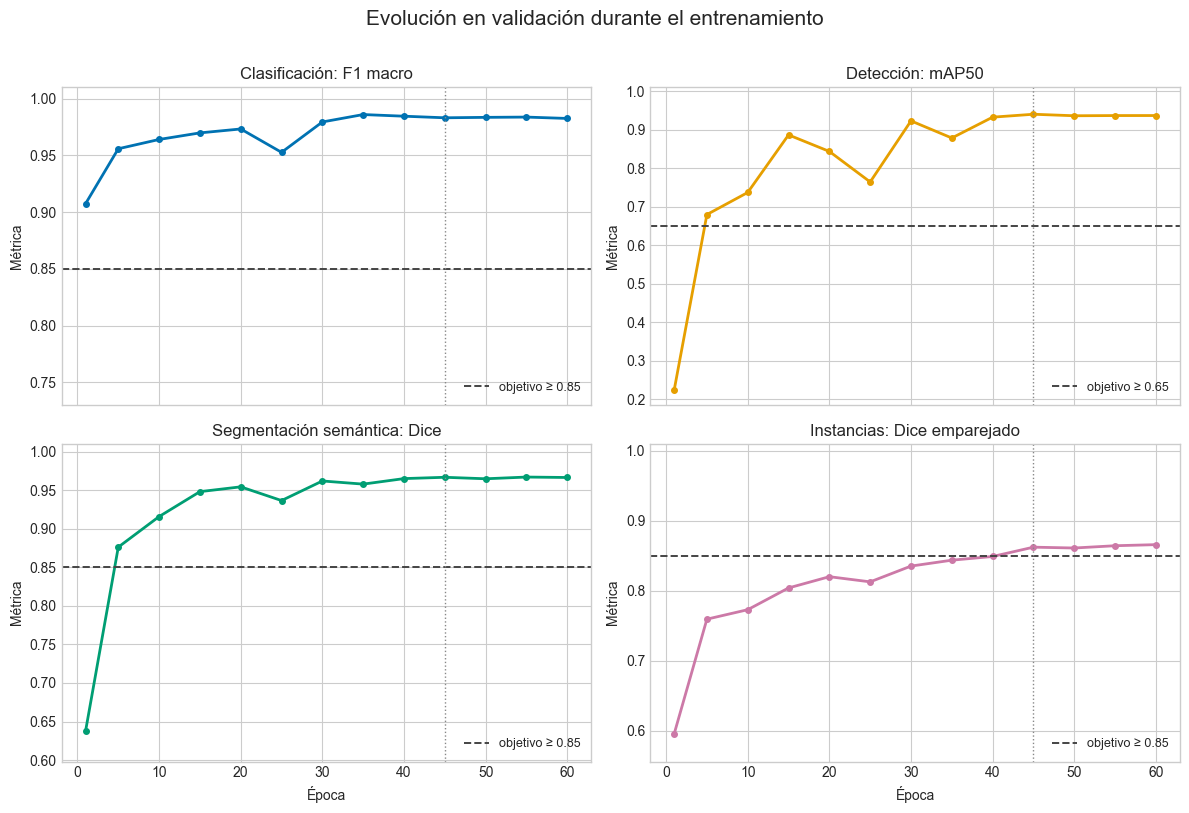

Guardada: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu_25d\figures\metricas_entrenamiento_25d.png


In [7]:
paneles = [
    ("classification_f1_macro", "Clasificación: F1 macro", 0.85, "#0072B2"),
    ("detection_map50", "Detección: mAP50", 0.65, "#E69F00"),
    ("segmentation_dice_macro", "Segmentación semántica: Dice", 0.85, "#009E73"),
    ("instance_dice_matched", "Instancias: Dice emparejado", 0.85, "#CC79A7"),
]
fig, ejes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, (clave, titulo, objetivo, color) in zip(ejes.ravel(), paneles):
    ax.plot(historial["epoch"], historial[clave], marker="o", markersize=4, color=color, linewidth=2)
    ax.axhline(objetivo, color="#444444", linestyle="--", linewidth=1.4, label=f"objetivo ≥ {objetivo:.2f}")
    ax.axvline(epoca_mejor, color="#888888", linestyle=":", linewidth=1)
    ax.set_title(titulo)
    ax.set_ylim(max(0, min(objetivo - 0.12, historial[clave].min() - 0.04)), 1.01)
    ax.set_ylabel("Métrica")
    ax.legend(loc="lower right", fontsize=9)
for ax in ejes[-1]: ax.set_xlabel("Época")
fig.suptitle("Evolución en validación durante el entrenamiento", fontsize=15, y=1.01)
fig.tight_layout()
ruta_metricas = FIGURAS / "metricas_entrenamiento_25d.png"
fig.savefig(ruta_metricas, dpi=170, bbox_inches="tight")
plt.show()
print("Guardada:", ruta_metricas)

## 5. Cumplimiento de las nueve metas

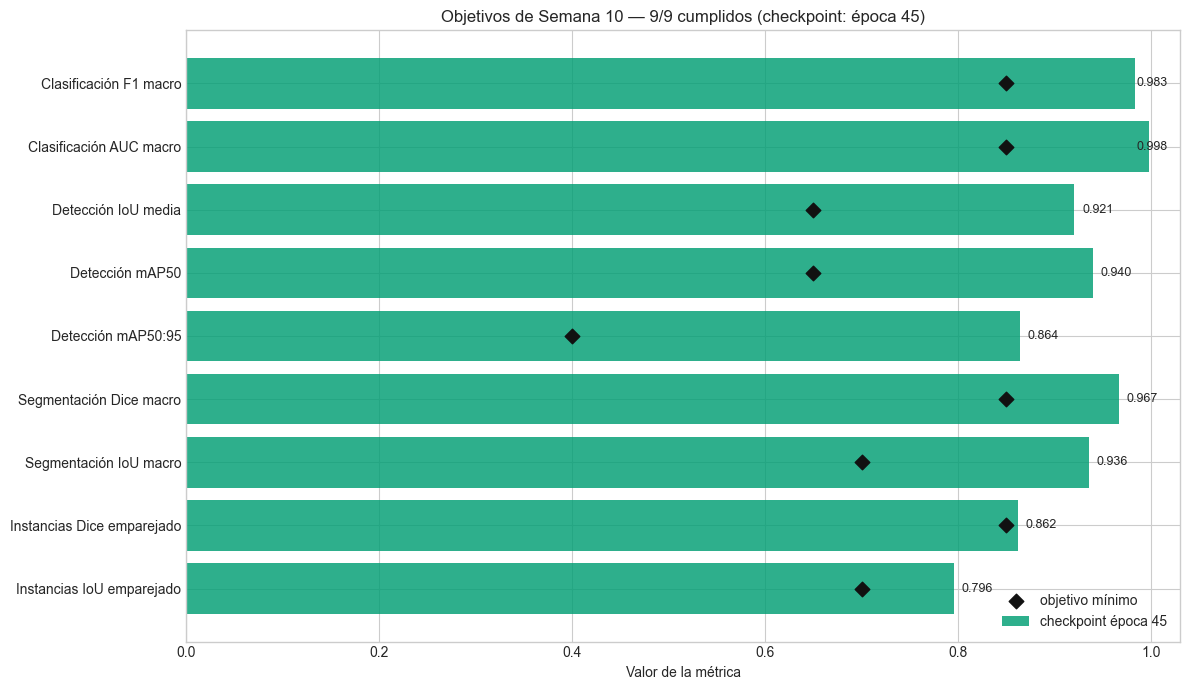

Guardada: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu_25d\figures\cumplimiento_objetivos_25d.png


In [8]:
nombres = [OBJETIVOS[c][0] for c in OBJETIVOS]
valores = np.array([float(mejor[c]) for c in OBJETIVOS])
metas = np.array([OBJETIVOS[c][1] for c in OBJETIVOS])
y = np.arange(len(nombres))
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(y, valores, color="#009E73", alpha=0.82, label=f"checkpoint época {epoca_mejor}")
ax.scatter(metas, y, marker="D", s=55, color="#111111", zorder=5, label="objetivo mínimo")
for i, valor in enumerate(valores):
    ax.text(min(valor + 0.008, 0.985), i, f"{valor:.3f}", va="center", fontsize=9)
ax.set_yticks(y, nombres)
ax.invert_yaxis()
ax.set_xlim(0, 1.03)
ax.set_xlabel("Valor de la métrica")
ax.set_title(f"Objetivos de Semana 10 — 9/9 cumplidos (checkpoint: época {epoca_mejor})")
ax.legend(loc="lower right")
fig.tight_layout()
ruta_objetivos = FIGURAS / "cumplimiento_objetivos_25d.png"
fig.savefig(ruta_objetivos, dpi=170, bbox_inches="tight")
plt.show()
print("Guardada:", ruta_objetivos)

## 6. Evaluación volumétrica completa (opcional)

Esta etapa vuelve a inferir los 15 pacientes de validación y puede tardar bastante. Está **desactivada por defecto**. Para ejecutarla cambia la variable a `True` y corre solamente las dos celdas siguientes. No se vuelve a entrenar.

In [9]:
EJECUTAR_EVALUACION_VOLUMETRICA = False
BATCH_SIZE_EVALUACION = 2
comando_evaluacion = [
    sys.executable, "src/evaluate_volumes.py",
    "--checkpoint", str(CHECKPOINT),
    "--cache-dir", str(ROOT / "data" / "cache" / "s10" / "cache_384"),
    "--split", "val", "--batch-size", str(BATCH_SIZE_EVALUACION),
    "--tta", "--output", str(VALIDACION_JSON),
]
print("Evaluación automática:", EJECUTAR_EVALUACION_VOLUMETRICA)
print("Salida esperada:", VALIDACION_JSON)

Evaluación automática: False
Salida esperada: E:\Proyecto_2_Analytics\proyecto2-analitica-datos-main\outputs\s10\local_gpu_25d\h6_25d_noema_nocudnn_w32_e60_s42_local_val.json


In [10]:
import subprocess
import time

def ejecutar_visible(comando, titulo, log_path=None):
    print(f"\n=== {titulo} ===")
    print(" ".join(map(str, comando)))
    inicio = time.time()
    with subprocess.Popen(comando, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, encoding="utf-8", errors="replace", bufsize=1) as proceso:
        lineas = []
        for linea in proceso.stdout:
            print(linea, end="")
            lineas.append(linea)
        codigo = proceso.wait()
    if log_path is not None: log_path.write_text("".join(lineas), encoding="utf-8")
    print(f"=== finalizó con código {codigo} en {(time.time() - inicio) / 60:.1f} min ===")
    if codigo != 0: raise RuntimeError(f"El comando terminó con código {codigo}.")

if VALIDACION_JSON.exists():
    print("La evaluación volumétrica ya existe; no se repite:", VALIDACION_JSON)
elif EJECUTAR_EVALUACION_VOLUMETRICA:
    ejecutar_visible(comando_evaluacion, "Evaluación volumétrica 2.5D", LOG_VALIDACION)
else:
    print("Omitida correctamente. Actívala solo si necesitas métricas 3D/TTA por paciente.")

Omitida correctamente. Actívala solo si necesitas métricas 3D/TTA por paciente.


In [11]:
if VALIDACION_JSON.exists():
    with VALIDACION_JSON.open(encoding="utf-8") as f: validacion = json.load(f)
    display(Markdown("### Resultado de la evaluación volumétrica"))
    display(pd.Series(validacion.get("aggregate", validacion)).to_frame("valor") if isinstance(validacion, dict) else validacion)
else:
    display(Markdown("**Todavía no hay JSON volumétrico completo.** Esto no afecta las gráficas ni las nueve métricas recuperadas. La celda anterior permite generarlo sin reentrenar."))

**Todavía no hay JSON volumétrico completo.** Esto no afecta las gráficas ni las nueve métricas recuperadas. La celda anterior permite generarlo sin reentrenar.

## Conclusión recuperada

- El entrenamiento terminó las **60 épocas**.
- El mejor score compuesto y el checkpoint guardado corresponden a la **época 45**.
- El checkpoint está libre de **NaN** e **Inf**.
- El modelo cumplió **9 de 9 objetivos**.
- Las figuras también quedan como PNG en `outputs/s10/local_gpu_25d/figures/`.